# 07 - High-confidence breaks

| | |
|---|---|
| **Milestone** | Milestone 1 |
| **Task** | M1-W7 (pre-registered Task 2) |
| **Stage** | Stage 2 (shift detection) |
| **Aim** | Keep only breaks that PELT confirms, that are large, and that persist. |
| **Inputs** | `data/interim/*_candidates.csv`<br>`outputs/tables/break_calibration.csv` |
| **Outputs** | `outputs/tables/hc_breaks_*.csv` |
| **Hypotheses** | Task 2 (descriptive) |
| **Expected runtime** | about 2 min |

# 07 - High-confidence breaks (pre-registered Task 2)

Definition fixed in `docs/PREREGISTRATION.md`. A CUSUM break (first break over the full series, frozen threshold) is **high-confidence** if all hold:
1. **Agreement:** a PELT changepoint within ±8 weeks (56 days) of the CUSUM change week.
2. **Effect size:** |post − pre| / pre ≥ 20% (pre = 26 weeks before; post = weeks 1–26 after).
3. **Persistence:** the shift keeps at least half its size in weeks 27–52 after. Breaks with fewer than 52 weeks after the change are "not assessable" and not high-confidence.

This is an offline description of the breaks (it uses data after each break). The no-lookahead version used for forecasting is applied in the Task 3 notebook.

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from break_detection import to_weekly, cusum_detect
from calibration import pelt_changepoints
from break_quality import assess_break, break_position

BURN_IN, REF_LEN, K = 8, 52, 1.0
MONITOR_START = BURN_IN + REF_LEN
calib = pd.read_csv("../outputs/tables/break_calibration.csv").set_index('method')
H, PEN = float(calib.loc['CUSUM', 'value']), float(calib.loc['PELT', 'value'])

rows = []
for cat in ['foods', 'hobbies', 'household']:
    df = pd.read_csv(f"../data/interim/{cat}_candidates.csv", parse_dates=['date'])
    for item, g in df.groupby('item_id'):
        w = to_weekly(g.sort_values('date'))
        v = w.to_numpy()
        res = cusum_detect(v, burn_in=BURN_IN, ref_len=REF_LEN, k=K, h=H)
        row = {'item_id': item, 'category': cat.upper(), 'n_weeks': len(v),
               'cusum_break': res is not None and res['alarm_idx'] is not None}
        if row['cusum_break']:
            c = res['change_idx']
            cps = pelt_changepoints(v, PEN, BURN_IN, REF_LEN)
            a = assess_break(v, c, cps)
            row.update(change_week=w.index[c], alarm_week=w.index[res['alarm_idx']], direction=res['direction'],
                       weeks_to_nearest_pelt=min((abs(cp - c) for cp in cps), default=np.nan), **a,
                       **break_position(v, c, res['direction'], MONITOR_START, a['pre_mean'], a['post_mean']))
        rows.append(row)
items = pd.DataFrame(rows)
items.to_csv("../outputs/tables/hc_breaks_items.csv", index=False)
breaks = items[items['cusum_break']].copy()
BOOL_COLS = ['agreement', 'effect', 'assessable', 'persistence', 'high_confidence', 'in_launch_ramp', 'near_series_end',
             'last_8_weeks_zero', 'post_below_10pct_of_pre', 'possible_delisting_artifact']
breaks[BOOL_COLS] = breaks[BOOL_COLS].astype(bool)      # object dtype otherwise (NaN on no-break rows)
print(f"{len(items)} items, {len(breaks)} with a CUSUM break")

726 items, 488 with a CUSUM break


## Counts at each step of the filter

In [2]:
def funnel(all_items, b):
    step1 = b['agreement']
    step2 = step1 & b['effect']
    step3 = step2 & b['assessable']
    step4 = step3 & b['persistence']
    return pd.Series({
        'items': len(all_items), 'cusum_breaks': len(b),
        '1_pelt_agrees': int(step1.sum()), '2_and_effect_20pct': int(step2.sum()),
        '3_and_assessable': int(step3.sum()), '4_high_confidence': int(step4.sum()),
        'hc_share_of_breaks': step4.mean(), 'hc_share_of_items': step4.sum() / len(all_items),
        'alone_agreement': b['agreement'].mean(), 'alone_effect': b['effect'].mean(),
        'alone_assessable': b['assessable'].mean(),
        'alone_persistence_if_assessable': b.loc[b['assessable'], 'persistence'].mean()})

fun = pd.DataFrame({'ALL': funnel(items, breaks),
                    **{c: funnel(items[items['category'] == c], g) for c, g in breaks.groupby('category')}}).T
fun.to_csv("../outputs/tables/hc_breaks_funnel.csv")
pd.set_option('display.width', 220)
count_cols = ['items', 'cusum_breaks', '1_pelt_agrees', '2_and_effect_20pct', '3_and_assessable', '4_high_confidence']
print(fun[count_cols].astype(int).to_string())
print()
print(fun.drop(columns=count_cols).round(3).to_string())

           items  cusum_breaks  1_pelt_agrees  2_and_effect_20pct  3_and_assessable  4_high_confidence
ALL          726           488            316                 296               279                171
FOODS        337           234            149                 138               129                 67
HOBBIES      106            68             45                  44                42                 29
HOUSEHOLD    283           186            122                 114               108                 75

           hc_share_of_breaks  hc_share_of_items  alone_agreement  alone_effect  alone_assessable  alone_persistence_if_assessable
ALL                     0.350              0.236            0.648         0.863             0.943                            0.639
FOODS                   0.286              0.199            0.637         0.859             0.932                            0.578
HOBBIES                 0.426              0.274            0.662         0.912            

## Direction, and where breaks fall in the series

In [3]:
breaks['group'] = np.where(breaks['high_confidence'], 'high-confidence', 'other breaks')

def position(g):
    return pd.Series({
        'n': len(g),
        'down_share': (g['direction'] < 0).mean(),
        'median_weeks_since_first_sale': g['weeks_since_first_sale'].median(),
        'median_position_share': g['position_share'].median(),
        'in_launch_ramp': g['in_launch_ramp'].mean(),
        'near_series_end': g['near_series_end'].mean(),
        'last_8_weeks_zero': g['last_8_weeks_zero'].mean(),
        'post_below_10pct_of_pre': g['post_below_10pct_of_pre'].mean(),
        'possible_delisting_artifact': g['possible_delisting_artifact'].mean(),
        'median_abs_relative_change': g['relative_change'].abs().median()})

pos = pd.concat([
    breaks.groupby('group').apply(position, include_groups=False),
    breaks.groupby('category').apply(position, include_groups=False),
    pd.DataFrame({'ALL breaks': position(breaks)}).T])
pos.to_csv("../outputs/tables/hc_breaks_position.csv")
print(pos.round(3).to_string())

hc = breaks[breaks['high_confidence']]
print("\nHigh-confidence breaks by category and direction:")
print(pd.crosstab(hc['category'], hc['direction'].map({1: 'up', -1: 'down'}), margins=True).to_string())
print(f"\nPossible delisting artifacts: {int(breaks['possible_delisting_artifact'].sum())} of {len(breaks)} breaks, "
      f"of which {int(hc['possible_delisting_artifact'].sum())} are high-confidence")
uniform_ramp = 26 / (breaks['n_weeks'] - 1 - MONITOR_START)
print(f"If change weeks were uniform over each item's monitoring period, {uniform_ramp.mean():.3f} would fall in the "
      f"launch ramp; observed {breaks['in_launch_ramp'].mean():.3f}")

                     n  down_share  median_weeks_since_first_sale  median_position_share  in_launch_ramp  near_series_end  last_8_weeks_zero  post_below_10pct_of_pre  possible_delisting_artifact  median_abs_relative_change
high-confidence  171.0       0.649                           97.0                  0.375           0.398            0.000              0.000                    0.058                        0.058                       0.498
other breaks     317.0       0.644                          104.0                  0.402           0.385            0.016              0.003                    0.028                        0.032                       0.408
FOODS            234.0       0.641                          105.0                  0.405           0.346            0.017              0.000                    0.047                        0.047                       0.442
HOBBIES           68.0       0.750                           97.0                  0.374           0.441    

direction  down  up  All
category                
FOODS        48  19   67
HOBBIES      19  10   29
HOUSEHOLD    44  31   75
All         111  60  171

Possible delisting artifacts: 20 of 488 breaks, of which 10 are high-confidence
If change weeks were uniform over each item's monitoring period, 0.138 would fall in the launch ramp; observed 0.389


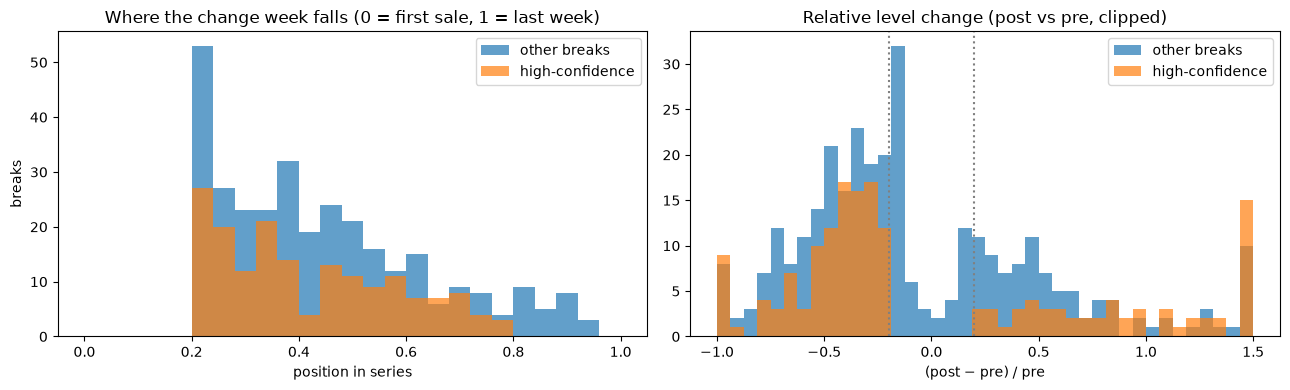

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.linspace(0, 1, 26)
axes[0].hist(breaks.loc[~breaks['high_confidence'], 'position_share'], bins=bins, alpha=0.7, label='other breaks')
axes[0].hist(hc['position_share'], bins=bins, alpha=0.7, label='high-confidence')
axes[0].set(title='Where the change week falls (0 = first sale, 1 = last week)', xlabel='position in series', ylabel='breaks')
axes[0].legend()
rc = breaks['relative_change'].clip(-1, 1.5)
axes[1].hist(rc[~breaks['high_confidence']], bins=40, alpha=0.7, label='other breaks')
axes[1].hist(rc[breaks['high_confidence']], bins=40, alpha=0.7, label='high-confidence')
for x in (-0.2, 0.2):
    axes[1].axvline(x, color='grey', ls=':')
axes[1].set(title='Relative level change (post vs pre, clipped)', xlabel='(post − pre) / pre')
axes[1].legend()
plt.tight_layout()
plt.savefig("../outputs/figures/hc_breaks_position_effect.png", dpi=120)
plt.show()